In [1]:
import pandas as pd

leagues = {"E0": "Premier League", "D1": "Bundesliga", "SP1": "La Liga",
           "I1": "Serie A", "F1": "Ligue 1"}
seasons = ["1718", "1819", "1920", "2021", "2122", "2223"]

frames = []
for code, name in leagues.items():
    for s in seasons:
        url = f"https://www.football-data.co.uk/mmz4281/{s}/{code}.csv"
        try:
            df = pd.read_csv(url, encoding="latin-1")
            df["League"] = name
            df["Season"] = s
            frames.append(df)
        except Exception as e:
            print("не загрузилось:", code, s, e)

data = pd.concat(frames, ignore_index=True)
print(data.shape)
data.head()

(10855, 130)


,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,ï»¿Div
0,E0,11/08/2017,Arsenal,Leicester,4,3,H,2,2,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,12/08/2017,Brighton,Man City,0,2,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,12/08/2017,Chelsea,Burnley,2,3,A,0,3,A,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,12/08/2017,Crystal Palace,Huddersfield,0,3,A,0,2,A,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,12/08/2017,Everton,Stoke,1,0,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
# 1. Починить колонку Div: склеить обе версии в одну
data["Div"] = data["Div"].fillna(data["ï»¿Div"])
data = data.drop(columns=["ï»¿Div"])

# 2. Оставить только нужные столбцы
cols = ["League", "Season", "Div", "Date", "HomeTeam", "AwayTeam",
        "FTHG", "FTAG", "Referee", "HS", "AS", "HF", "AF",
        "HY", "AY", "HR", "AR"]
for c in ["HO", "AO"]:          # офсайды, если они есть
    if c in data.columns:
        cols.append(c)

df = data[cols].copy()
df = df.dropna(subset=["HomeTeam"])   # убрать пустые строки

# 3. Проверка: пропуски, дубликаты, сколько матчей в каждой лиге и сезоне
print("Пропуски по столбцам:")
print(df.isna().sum())
print()
print("Дубликаты:", df.duplicated(subset=["Div", "Date", "HomeTeam", "AwayTeam"]).sum())
print()
print(df.groupby(["League", "Season"]).size().unstack())

Пропуски по столбцам:
League         0
Season         0
Div            0
Date           0
HomeTeam       0
AwayTeam       0
FTHG           0
FTAG           0
Referee     8575
HS             0
AS             0
HF             0
AF             0
HY             0
AY             0
HR             0
AR             0
dtype: int64

Дубликаты: 0

Season          1718  1819  1920  2021  2122  2223
League                                            
Bundesliga       306   306   306   306   306   306
La Liga          380   380   380   380   380   380
Ligue 1          380   380   279   380   380   380
Premier League   380   380   380   380   380   380
Serie A          380   380   380   380   380   380


In [3]:
# 1. Привести дату к нормальному виду (в файлах разные форматы)
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, format="mixed")

# 2. Метка периода по зрителям
def period(row):
    if row["Date"] < pd.Timestamp("2020-03-01"):
        return "1_crowd"            # обычные матчи до COVID
    if row["Date"] < pd.Timestamp("2020-05-16"):
        return "x_pause"            # пауза и переходный период
    if row["Season"] == "1920":
        return "2_empty"            # возобновление 2019/20: стадионы пустые
    if row["Season"] == "2021":
        return "3_mostly_empty"     # 2020/21: пустые, местами с частью зрителей
    return "4_crowd_back"           # 2021/22 и 2022/23: зрители вернулись

df["Period"] = df.apply(period, axis=1)
print(df["Period"].value_counts())

# 3. Главная метрика: жёлтые карточки на один фол
def card_rates(g):
    home = g["HY"].sum() / g["HF"].sum()
    away = g["AY"].sum() / g["AF"].sum()
    return pd.Series({"matches": len(g),
                      "home_cards_per_foul": home,
                      "away_cards_per_foul": away,
                      "gap_away_minus_home": away - home})

res = (df[df["Period"] != "x_pause"]
       .groupby("Period").apply(card_rates).round(4))
res

Period
1_crowd           4909
4_crowd_back      3652
3_mostly_empty    1826
2_empty            408
x_pause             60
Name: count, dtype: int64


/tmp/ipykernel_4082/3307848837.py:29: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby("Period").apply(card_rates).round(4))


,matches,home_cards_per_foul,away_cards_per_foul,gap_away_minus_home
Period,,,,
1_crowd,4909.0,0.1547,0.1715,0.0168
2_empty,408.0,0.1622,0.1530,-0.0092
3_mostly_empty,1826.0,0.1495,0.1560,0.0066
4_crowd_back,3652.0,0.1623,0.1818,0.0195


In [4]:
import numpy as np
rng = np.random.default_rng(42)

def boot_gap(g, n=2000):
    HY, HF, AY, AF = (g[c].to_numpy() for c in ["HY", "HF", "AY", "AF"])
    m = len(g)
    gaps = np.empty(n)
    for i in range(n):
        idx = rng.integers(0, m, m)      # случайная выборка матчей с повторами
        gaps[i] = AY[idx].sum() / AF[idx].sum() - HY[idx].sum() / HF[idx].sum()
    return gaps

periods = ["1_crowd", "2_empty", "3_mostly_empty", "4_crowd_back"]
boots = {p: boot_gap(df[df["Period"] == p]) for p in periods}

for p in periods:
    lo, hi = np.percentile(boots[p], [2.5, 97.5])
    print(f"{p:15s} разница = {boots[p].mean():+.4f}   95% интервал: [{lo:+.4f}; {hi:+.4f}]")

# главный вопрос: отличается ли разница со зрителями от разницы без зрителей?
d = boots["1_crowd"] - boots["2_empty"]
lo, hi = np.percentile(d, [2.5, 97.5])
print(f"\nCrowd минус Empty: {d.mean():+.4f}   95% интервал: [{lo:+.4f}; {hi:+.4f}]")
print("Доля случаев, когда crowd > empty:", (d > 0).mean())

1_crowd         разница = +0.0168   95% интервал: [+0.0130; +0.0205]
2_empty         разница = -0.0091   95% интервал: [-0.0211; +0.0024]
3_mostly_empty  разница = +0.0065   95% интервал: [+0.0006; +0.0124]
4_crowd_back    разница = +0.0194   95% интервал: [+0.0149; +0.0237]

Crowd минус Empty: +0.0259   95% интервал: [+0.0138; +0.0387]
Доля случаев, когда crowd > empty: 1.0


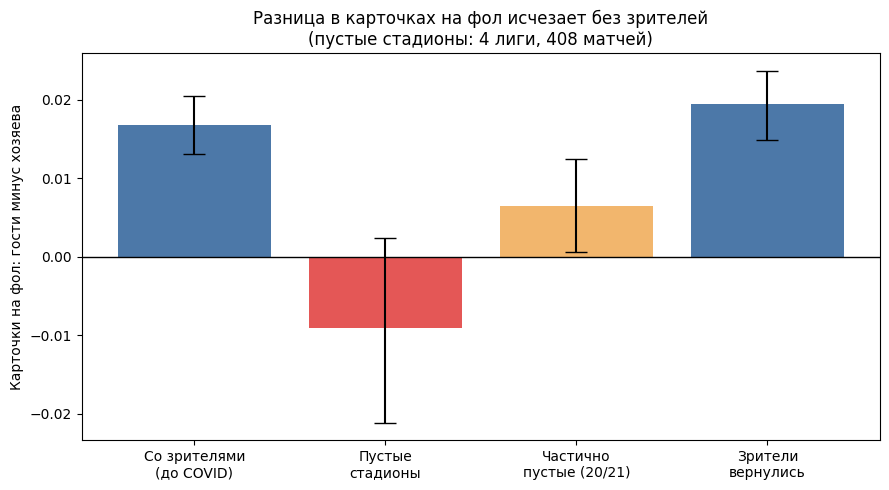

In [5]:
import matplotlib.pyplot as plt

labels = ["Со зрителями\n(до COVID)", "Пустые\nстадионы", "Частично\nпустые (20/21)", "Зрители\nвернулись"]
means = [boots[p].mean() for p in periods]
los   = [np.percentile(boots[p], 2.5) for p in periods]
his   = [np.percentile(boots[p], 97.5) for p in periods]
err   = [[m - l for m, l in zip(means, los)], [h - m for m, h in zip(means, his)]]

plt.figure(figsize=(9, 5))
plt.bar(labels, means, yerr=err, capsize=8,
        color=["#4c78a8", "#e45756", "#f2b66d", "#4c78a8"])
plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Карточки на фол: гости минус хозяева")
plt.title("Разница в карточках на фол исчезает без зрителей\n(пустые стадионы: 4 лиги, 408 матчей)")
plt.tight_layout()
plt.savefig("main_chart.png", dpi=200)
plt.show()

In [6]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

d = df[df["Period"].isin(["1_crowd", "2_empty", "4_crowd_back"])].copy()
d["match_id"] = range(len(d))

# каждый матч превращаем в две строки: хозяева и гости
home = pd.DataFrame({"match_id": d["match_id"], "League": d["League"],
                     "Period": d["Period"], "is_home": 1,
                     "yellow": d["HY"], "fouls": d["HF"],
                     "shot_diff": d["HS"] - d["AS"]})
away = pd.DataFrame({"match_id": d["match_id"], "League": d["League"],
                     "Period": d["Period"], "is_home": 0,
                     "yellow": d["AY"], "fouls": d["AF"],
                     "shot_diff": d["AS"] - d["HS"]})
long = pd.concat([home, away], ignore_index=True)
long = long[long["fouls"] > 0].copy()
long["empty"] = (long["Period"] == "2_empty").astype(int)
long["log_fouls"] = np.log(long["fouls"])

model = smf.glm("yellow ~ is_home * empty + shot_diff + C(League)",
                data=long, family=sm.families.Poisson(),
                offset=long["log_fouls"]).fit(cov_type="HC1")

keep = ["is_home", "empty", "is_home:empty", "shot_diff"]
out = pd.DataFrame({"коэф": model.params[keep],
                    "во_сколько_раз": np.exp(model.params[keep]),
                    "p-value": model.pvalues[keep]}).round(4)
print(len(long), "строк (команда-матч)")
out

17934 строк (команда-матч)


,коэф,во_сколько_раз,p-value
is_home,-0.0735,0.9292,0.0000
empty,-0.1635,0.8492,0.0000
is_home:empty,0.1453,1.1564,0.0013
shot_diff,-0.0072,0.9928,0.0000


In [7]:
model2 = smf.glm("yellow ~ is_home * empty + shot_diff + C(League)",
                 data=long, family=sm.families.Poisson(),
                 offset=long["log_fouls"]).fit(
                     cov_type="cluster", cov_kwds={"groups": long["match_id"]})

keep = ["is_home", "empty", "is_home:empty", "shot_diff"]
out2 = pd.DataFrame({"во_сколько_раз": np.exp(model2.params[keep]),
                     "p-value": model2.pvalues[keep]}).round(4)
print(out2)

# эффект хозяев именно в пустых матчах: is_home + is_home:empty = 0 ?
t = model2.t_test("is_home + is_home:empty = 0")
print("\nЭффект хозяев в пустых матчах: во сколько раз =",
      round(float(np.exp(t.effect[0])), 4), " p-value =", round(float(t.pvalue), 4))

               во_сколько_раз  p-value
is_home                0.9292   0.0000
empty                  0.8492   0.0000
is_home:empty          1.1564   0.0003
shot_diff              0.9928   0.0000

Эффект хозяев в пустых матчах: во сколько раз = 1.0745  p-value = 0.0665


In [8]:
rows = []
for lg in df["League"].unique():
    for p in ["1_crowd", "2_empty"]:
        g = df[(df["League"] == lg) & (df["Period"] == p)]
        gaps = boot_gap(g, n=1000)
        rows.append({"League": lg, "Period": p, "matches": len(g),
                     "gap": gaps.mean(),
                     "lo": np.percentile(gaps, 2.5),
                     "hi": np.percentile(gaps, 97.5)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

        League  Period  matches     gap      lo     hi
Premier League 1_crowd     1036  0.0096  0.0009 0.0185
Premier League 2_empty       92 -0.0051 -0.0288 0.0182
    Bundesliga 1_crowd      824  0.0211  0.0126 0.0296
    Bundesliga 2_empty       82 -0.0098 -0.0380 0.0205
       La Liga 1_crowd     1014  0.0149  0.0065 0.0231
       La Liga 2_empty      110 -0.0214 -0.0454 0.0040
       Serie A 1_crowd     1008  0.0215  0.0136 0.0294
       Serie A 2_empty      124 -0.0007 -0.0223 0.0205
       Ligue 1 1_crowd     1027  0.0178  0.0107 0.0256
       Ligue 1 2_empty        0     NaN     NaN    NaN


/tmp/ipykernel_4082/2232227543.py:10: RuntimeWarning: invalid value encountered in scalar divide
  gaps[i] = AY[idx].sum() / AF[idx].sum() - HY[idx].sum() / HF[idx].sum()


ML

In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance

d = df[df["Period"].isin(["1_crowd", "2_empty"])].copy()

home = pd.DataFrame({"Date": d["Date"], "Period": d["Period"], "League": d["League"],
                     "is_home": 1, "yellow": d["HY"], "fouls": d["HF"],
                     "shots": d["HS"], "shot_diff": d["HS"] - d["AS"]})
away = pd.DataFrame({"Date": d["Date"], "Period": d["Period"], "League": d["League"],
                     "is_home": 0, "yellow": d["AY"], "fouls": d["AF"],
                     "shots": d["AS"], "shot_diff": d["AS"] - d["HS"]})
m = pd.concat([home, away], ignore_index=True)
m = pd.concat([m, pd.get_dummies(m["League"], prefix="lg", dtype=int)], axis=1)
lg_cols = [c for c in m.columns if c.startswith("lg_")]

# разбиение по времени
train = m[(m["Period"] == "1_crowd") & (m["Date"] < "2019-07-01")]   # сезоны 17/18 и 18/19
valid = m[(m["Period"] == "1_crowd") & (m["Date"] >= "2019-07-01")]  # 19/20 до COVID, зрители
test  = m[m["Period"] == "2_empty"]                                  # пустые стадионы
print("train:", len(train), " valid:", len(valid), " test (пустые):", len(test))

base_feats = ["fouls", "shots", "shot_diff"] + lg_cols
feats_home = base_feats + ["is_home"]

# Базовая модель: средние карточки на фол по лиге (из train) * число фолов
rate = train.groupby("League").apply(lambda g: g["yellow"].sum() / g["fouls"].sum())
def baseline(x):
    return x["fouls"] * x["League"].map(rate)

gbm_a = HistGradientBoostingRegressor(loss="poisson", max_depth=3, learning_rate=0.05,
                                      max_iter=200, random_state=42)
gbm_b = HistGradientBoostingRegressor(loss="poisson", max_depth=3, learning_rate=0.05,
                                      max_iter=200, random_state=42)
gbm_a.fit(train[base_feats], train["yellow"])      # без is_home
gbm_b.fit(train[feats_home], train["yellow"])      # с is_home

def score(x, name):
    preds = {"baseline": baseline(x),
             "GBM без is_home": gbm_a.predict(x[base_feats]),
             "GBM с is_home": gbm_b.predict(x[feats_home])}
    rows = []
    for k, p in preds.items():
        p = np.clip(p, 1e-3, None)
        rows.append({"набор": name, "модель": k,
                     "MAE": mean_absolute_error(x["yellow"], p),
                     "Poisson dev.": mean_poisson_deviance(x["yellow"], p)})
    return pd.DataFrame(rows)

print(pd.concat([score(valid, "valid (зрители)"), score(test, "test (пустые)")]).round(4).to_string(index=False))

# Главный тест: систематическая ошибка (факт − прогноз) отдельно для хозяев и гостей
for name, x in [("valid (зрители)", valid), ("test (пустые)", test)]:
    res = x["yellow"] - gbm_b.predict(x[feats_home])
    print(f"\n{name}: средняя ошибка (факт − прогноз), карточек за команду-матч")
    print(res.groupby(x["is_home"]).mean().rename({0: "гости", 1: "хозяева"}).round(4))

train: 7304  valid: 2514  test (пустые): 816


/tmp/ipykernel_4082/1019441759.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rate = train.groupby("League").apply(lambda g: g["yellow"].sum() / g["fouls"].sum())


          набор          модель    MAE  Poisson dev.
valid (зрители)        baseline 0.9972        0.8783
valid (зрители) GBM без is_home 1.0028        0.8714
valid (зрители)   GBM с is_home 0.9997        0.8676
  test (пустые)        baseline 1.0212        0.9787
  test (пустые) GBM без is_home 1.0234        0.9630
  test (пустые)   GBM с is_home 1.0288        0.9697

valid (зрители): средняя ошибка (факт − прогноз), карточек за команду-матч
is_home
гости      0.2017
хозяева    0.1887
Name: yellow, dtype: float64

test (пустые): средняя ошибка (факт − прогноз), карточек за команду-матч
is_home
гости     -0.2335
хозяева    0.0762
Name: yellow, dtype: float64


In [10]:
from sklearn.inspection import permutation_importance

n = len(d)   # в m сначала идут хозяева (0..n-1), потом гости (n..2n-1) в том же порядке матчей

def match_gap(x):
    x = x.copy()
    x["res"] = x["yellow"] - gbm_b.predict(x[feats_home])
    x["mid"] = x.index % n
    w = x.pivot(index="mid", columns="is_home", values="res").dropna()
    return (w[0] - w[1]).to_numpy()      # ошибка гостей минус ошибка хозяев, по матчам

g_valid = match_gap(valid)
g_test  = match_gap(test)
print("valid: гости − хозяева =", round(g_valid.mean(), 4), " матчей:", len(g_valid))
print("test : гости − хозяева =", round(g_test.mean(), 4),  " матчей:", len(g_test))

rng = np.random.default_rng(42)
diffs = np.array([rng.choice(g_test, len(g_test)).mean() -
                  rng.choice(g_valid, len(g_valid)).mean() for _ in range(5000)])
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"\nСдвиг (test − valid): {diffs.mean():+.4f}   95% интервал: [{lo:+.4f}; {hi:+.4f}]")

# важность признаков для GBM с is_home (на valid)
pi = permutation_importance(gbm_b, valid[feats_home], valid["yellow"],
                            n_repeats=10, random_state=42)
imp = pd.Series(pi.importances_mean, index=feats_home).sort_values(ascending=False)
print("\nВажность признаков:")
print(imp.round(4).head(6))

valid: гости − хозяева = 0.013  матчей: 1257
test : гости − хозяева = -0.3097  матчей: 408

Сдвиг (test − valid): -0.3225   95% интервал: [-0.5005; -0.1505]

Важность признаков:
fouls         0.2572
lg_La Liga    0.0351
lg_Serie A    0.0287
shot_diff     0.0117
is_home       0.0062
shots         0.0060
dtype: float64


In [11]:
import numpy as np, pandas as pd
from scipy.stats import poisson
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance

leagues = {"E0": "Premier League", "D1": "Bundesliga", "SP1": "La Liga",
           "I1": "Serie A", "F1": "Ligue 1"}
seasons = ["1718","1819","1920","2021","2122","2223","2324","2425","2526","2627"]

frames = []
for code, name in leagues.items():
    for s in seasons:
        try:
            x = pd.read_csv(f"https://www.football-data.co.uk/mmz4281/{s}/{code}.csv",
                            encoding="latin-1")
            x["League"] = name
            frames.append(x)
        except Exception as e:
            print("не загрузилось:", code, s)

raw = pd.concat(frames, ignore_index=True)
cols = ["League","Date","HomeTeam","AwayTeam","HF","AF","HY","AY","HS","AS"]
g = raw[cols].dropna().copy()
g["Date"] = pd.to_datetime(g["Date"], dayfirst=True, format="mixed")

# одна строка = одна команда в одном матче
def side(is_home):
    me, op = ("Home", "Away") if is_home else ("Away", "Home")
    return pd.DataFrame({"League": g["League"], "Date": g["Date"],
        "team": g[me+"Team"], "is_home": int(is_home),
        "yellow": g[me[0]+"Y"], "fouls": g[me[0]+"F"], "shots": g[me[0]+"S"],
        "fouls_suffered": g[op[0]+"F"], "shots_conceded": g[op[0]+"S"]})

L = pd.concat([side(True), side(False)]).sort_values(["team","Date"]).reset_index(drop=True)

# форма команды: среднее за последние 6 матчей, СО СДВИГОМ на 1 (чтобы не подсмотреть сам матч)
form_cols = ["yellow","fouls","shots","fouls_suffered","shots_conceded"]
roll = L.groupby("team")[form_cols].transform(
    lambda s: s.rolling(6, min_periods=3).mean().shift(1))
roll.columns = ["f_" + c for c in form_cols]
L = pd.concat([L, roll], axis=1)

# для обучения убираем сезон 2020/21 (пустые стадионы), чтобы не смешивать режимы
covid = (L["Date"] >= "2020-03-01") & (L["Date"] < "2021-07-01")
M = L[~covid].dropna(subset=["f_yellow"]).copy()
M = pd.concat([M, pd.get_dummies(M["League"], prefix="lg", dtype=int)], axis=1)
lg_cols = [c for c in M.columns if c.startswith("lg_")]
feats = ["is_home"] + ["f_"+c for c in form_cols] + lg_cols

# разбиение по времени: обучение до лета 2024, тест — сезоны 24/25 и 25/26
train = M[M["Date"] < "2024-07-01"]
test  = M[(M["Date"] >= "2024-07-01") & (M["Date"] < "2026-07-01")]
print("train:", len(train), " test:", len(test))

gbm = HistGradientBoostingRegressor(loss="poisson", max_depth=3,
                                    learning_rate=0.05, max_iter=200, random_state=42)
gbm.fit(train[feats], train["yellow"])

lg_mean = train.groupby("League")["yellow"].mean()
preds = {"база 1: среднее по лиге": test["League"].map(lg_mean),
         "база 2: форма команды (последние 6)": test["f_yellow"],
         "GBM": gbm.predict(test[feats])}
rows = []
for k, p in preds.items():
    p = np.clip(np.asarray(p, dtype=float), 1e-3, None)
    rows.append({"модель": k, "MAE": mean_absolute_error(test["yellow"], p),
                 "Poisson dev.": mean_poisson_deviance(test["yellow"], p)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

train: 20212  test: 6982
                             модель    MAE  Poisson dev.
            база 1: среднее по лиге 1.1190        1.1205
база 2: форма команды (последние 6) 1.1541        1.2253
                                GBM 1.0905        1.0879


In [12]:
home_team, away_team = "Chelsea", "Man United"   # названия, как в football-data
league = "Premier League"

# проверка названий
names = sorted(L.loc[L["League"] == league, "team"].unique())
print([n for n in names if n in (home_team, away_team)])

def latest_form(team):
    t = L[L["team"] == team].sort_values("Date").tail(6)
    print(f"{team}: форма по 6 матчам, последний сыгран {t['Date'].max().date()}")
    return t[form_cols].mean()

def make_row(team, is_home):
    f = latest_form(team)
    row = {"is_home": is_home}
    row.update({"f_" + c: f[c] for c in form_cols})
    for c in lg_cols:
        row[c] = int(c == "lg_" + league)
    return pd.DataFrame([row])[feats]

lam_h = float(gbm.predict(make_row(home_team, 1))[0])
lam_a = float(gbm.predict(make_row(away_team, 0))[0])
lam_t = lam_h + lam_a
print(f"\nОжидаемые жёлтые: {home_team} {lam_h:.2f}, {away_team} {lam_a:.2f}, всего {lam_t:.2f}")

# распределение: сумма двух пуассоновских величин тоже пуассоновская
print("\nВероятность, что в матче будет не меньше k жёлтых:")
for k in range(2, 8):
    print(f"  ≥ {k}: {1 - poisson.cdf(k - 1, lam_t):.0%}")

print("\nВероятность для каждой команды получить не меньше k жёлтых:")
for k in range(1, 5):
    print(f"  ≥ {k}:  {home_team} {1 - poisson.cdf(k-1, lam_h):.0%}   {away_team} {1 - poisson.cdf(k-1, lam_a):.0%}")

['Chelsea', 'Man United']
Chelsea: форма по 6 матчам, последний сыгран 2026-10-24
Man United: форма по 6 матчам, последний сыгран 2026-10-25

Ожидаемые жёлтые: Chelsea 1.79, Man United 2.04, всего 3.83

Вероятность, что в матче будет не меньше k жёлтых:
  ≥ 2: 90%
  ≥ 3: 74%
  ≥ 4: 53%
  ≥ 5: 34%
  ≥ 6: 19%
  ≥ 7: 9%

Вероятность для каждой команды получить не меньше k жёлтых:
  ≥ 1:  Chelsea 83%   Man United 87%
  ≥ 2:  Chelsea 53%   Man United 61%
  ≥ 3:  Chelsea 27%   Man United 34%
  ≥ 4:  Chelsea 11%   Man United 15%


In [13]:
# 1. Загружаем только АПЛ с судьёй
ep = []
for s in ["1718","1819","1920","2021","2122","2223","2324","2425","2526","2627"]:
    try:
        x = pd.read_csv(f"https://www.football-data.co.uk/mmz4281/{s}/E0.csv", encoding="latin-1")
        x["Season"] = s
        ep.append(x)
    except Exception:
        print("не загрузилось:", s)
epl = pd.concat(ep, ignore_index=True)
epl = epl[["Season","Date","HomeTeam","AwayTeam","Referee","HY","AY"]].dropna()
epl["Date"] = pd.to_datetime(epl["Date"], dayfirst=True, format="mixed")
epl["total_y"] = epl["HY"] + epl["AY"]
epl = epl.sort_values("Date").reset_index(drop=True)

# 2. Есть ли у судьи устойчивый «почерк»? Сравниваем первую и вторую половину его матчей
stat = []
for ref, g in epl.groupby("Referee"):
    if len(g) >= 30:
        h = len(g) // 2
        stat.append({"ref": ref, "n": len(g),
                     "first_half": g["total_y"].iloc[:h].mean(),
                     "second_half": g["total_y"].iloc[h:].mean()})
stat = pd.DataFrame(stat)
print("Судей с ≥30 матчами:", len(stat))
print("Корреляция «первая половина — вторая половина»:",
      round(stat["first_half"].corr(stat["second_half"]), 3))

# 3. Данные по нашему судье
lg_avg = epl["total_y"].mean()
r = epl[epl["Referee"].str.contains("Bankes", case=False)]
print("\nСреднее число жёлтых в АПЛ за матч:", round(lg_avg, 2))
print("Matchей у Bankes:", len(r), "| среднее жёлтых:", round(r["total_y"].mean(), 2))

Судей с ≥30 матчами: 27
Корреляция «первая половина — вторая половина»: 0.615

Среднее число жёлтых в АПЛ за матч: 3.5
Matchей у Bankes: 120 | среднее жёлтых: 3.97


In [14]:
# 1. Сколько в карточках «шума» и сколько настоящих различий между судьями
refs = epl.groupby("Referee")["total_y"].agg(["mean", "count", "var"])
refs = refs[refs["count"] >= 30]

sigma2 = (refs["var"] * (refs["count"] - 1)).sum() / (refs["count"] - 1).sum()   # шум внутри судьи
tau2 = max(refs["mean"].var() - (sigma2 / refs["count"]).mean(), 1e-6)            # настоящие различия
k = sigma2 / tau2
print(f"шум внутри судьи σ²={sigma2:.2f}, настоящие различия τ²={tau2:.3f}, k={k:.1f}")

# 2. Сглаженная оценка для Бэнкса
n = len(r)
raw = r["total_y"].mean()
w = n / (n + k)
shrunk = lg_avg + w * (raw - lg_avg)
ratio = shrunk / lg_avg
print(f"Бэнкс: сырое среднее {raw:.2f} → сглаженное {shrunk:.2f} (вес данных {w:.0%})")
print(f"Поправочный множитель: {ratio:.3f}")

# 3. Пересчёт прогноза
lam_h2, lam_a2, lam_t2 = lam_h * ratio, lam_a * ratio, lam_t * ratio
print(f"\nОжидаемые жёлтые с учётом судьи: Chelsea {lam_h2:.2f}, Man United {lam_a2:.2f}, всего {lam_t2:.2f}")
print(f"(без судьи было {lam_t:.2f})")

print("\nВероятность, что в матче будет не меньше k жёлтых (до и после учёта судьи):")
for kk in range(2, 8):
    p0 = 1 - poisson.cdf(kk - 1, lam_t)
    p1 = 1 - poisson.cdf(kk - 1, lam_t2)
    print(f"  ≥ {kk}: {p0:.0%} → {p1:.0%}")

шум внутри судьи σ²=3.85, настоящие различия τ²=0.238, k=16.2
Бэнкс: сырое среднее 3.97 → сглаженное 3.91 (вес данных 88%)
Поправочный множитель: 1.116

Ожидаемые жёлтые с учётом судьи: Chelsea 1.99, Man United 2.28, всего 4.28
(без судьи было 3.83)

Вероятность, что в матче будет не меньше k жёлтых (до и после учёта судьи):
  ≥ 2: 90% → 93%
  ≥ 3: 74% → 80%
  ≥ 4: 53% → 62%
  ≥ 5: 34% → 43%
  ≥ 6: 19% → 26%
  ≥ 7: 9% → 14%


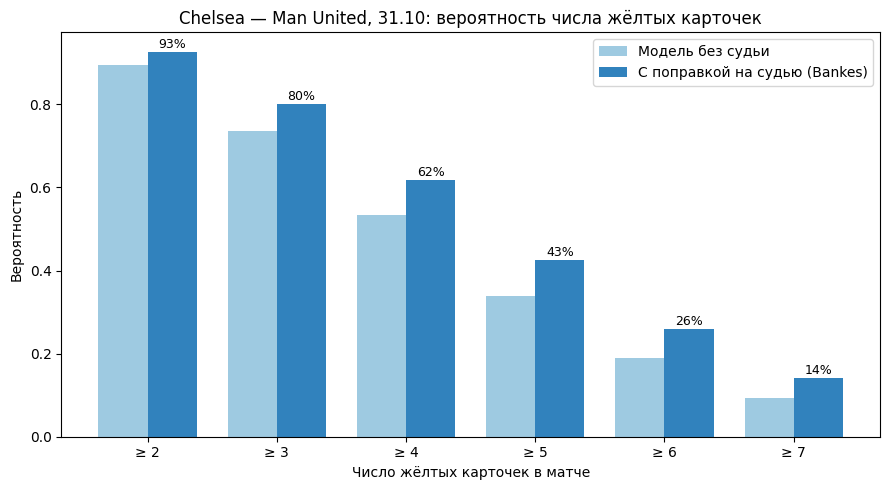

In [15]:
ks = list(range(2, 8))
p0 = [1 - poisson.cdf(k - 1, lam_t)  for k in ks]
p1 = [1 - poisson.cdf(k - 1, lam_t2) for k in ks]

x = np.arange(len(ks)); w_ = 0.38
plt.figure(figsize=(9, 5))
plt.bar(x - w_/2, p0, w_, label="Модель без судьи", color="#9ecae1")
plt.bar(x + w_/2, p1, w_, label="С поправкой на судью (Bankes)", color="#3182bd")
for i, v in enumerate(p1):
    plt.text(x[i] + w_/2, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
plt.xticks(x, [f"≥ {k}" for k in ks])
plt.xlabel("Число жёлтых карточек в матче")
plt.ylabel("Вероятность")
plt.title("Chelsea — Man United, 31.10: вероятность числа жёлтых карточек")
plt.legend()
plt.tight_layout()
plt.savefig("forecast_chart.png", dpi=200)
plt.show()

In [16]:
d = df.copy()
d["match_id"] = range(len(d))

def pts(gf, ga):
    return np.where(gf > ga, 3, np.where(gf == ga, 1, 0))

home = pd.DataFrame({"match_id": d["match_id"], "League": d["League"], "Season": d["Season"],
                     "Period": d["Period"], "team": d["HomeTeam"], "is_home": 1,
                     "yellow": d["HY"], "fouls": d["HF"], "shot_diff": d["HS"] - d["AS"],
                     "pts": pts(d["FTHG"], d["FTAG"])})
away = pd.DataFrame({"match_id": d["match_id"], "League": d["League"], "Season": d["Season"],
                     "Period": d["Period"], "team": d["AwayTeam"], "is_home": 0,
                     "yellow": d["AY"], "fouls": d["AF"], "shot_diff": d["AS"] - d["HS"],
                     "pts": pts(d["FTAG"], d["FTHG"])})
T = pd.concat([home, away], ignore_index=True)

# сила клуба: очки за матч в сезоне, разбиваем на 3 группы внутри лиги и сезона
ppg = T.groupby(["League", "Season", "team"])["pts"].mean().rename("ppg").reset_index()
ppg["pct"] = ppg.groupby(["League", "Season"])["ppg"].rank(pct=True)
ppg["tier"] = pd.cut(ppg["pct"], [0, 1/3, 2/3, 1.0], labels=["слабые", "средние", "сильные"],
                     include_lowest=True)
T = T.merge(ppg[["League", "Season", "team", "ppg", "tier"]], on=["League", "Season", "team"])

# режим: со зрителями / без зрителей (переходные периоды не берём)
T = T[T["Period"].isin(["1_crowd", "4_crowd_back", "2_empty"])].copy()
T["mode"] = np.where(T["Period"] == "2_empty", "без зрителей", "со зрителями")
T = T[T["fouls"] > 0]

# 1. карточки на фол по группам и режимам
tab = (T.groupby(["mode", "tier"], observed=True)
         .apply(lambda g: pd.Series({"строк": len(g), "карточек_на_фол": g["yellow"].sum() / g["fouls"].sum()}),
                include_groups=False)
         .round(4))
print(tab, "\n")

# 2. разрыв «слабые минус сильные» с интервалом (bootstrap)
rng = np.random.default_rng(7)
def rate_boot(g, n=3000):
    y, f = g["yellow"].to_numpy(), g["fouls"].to_numpy()
    m = len(g)
    out = np.empty(n)
    for i in range(n):
        idx = rng.integers(0, m, m)
        out[i] = y[idx].sum() / f[idx].sum()
    return out

gaps = {}
for mode in ["со зрителями", "без зрителей"]:
    weak = T[(T["mode"] == mode) & (T["tier"] == "слабые")]
    strong = T[(T["mode"] == mode) & (T["tier"] == "сильные")]
    gaps[mode] = rate_boot(weak) - rate_boot(strong)
    lo, hi = np.percentile(gaps[mode], [2.5, 97.5])
    print(f"{mode:14s} слабые − сильные = {gaps[mode].mean():+.4f}   95% интервал [{lo:+.4f}; {hi:+.4f}]")

dd = gaps["со зрителями"] - gaps["без зрителей"]
lo, hi = np.percentile(dd, [2.5, 97.5])
print(f"\nРазрыв со зрителями минус без зрителей: {dd.mean():+.4f}   95% интервал [{lo:+.4f}; {hi:+.4f}]")

                       строк  карточек_на_фол
mode         tier                            
без зрителей слабые    250.0           0.1626
             средние   285.0           0.1536
             сильные   281.0           0.1574
со зрителями слабые   5310.0           0.1719
             средние  5785.0           0.1656
             сильные  6023.0           0.1635 

со зрителями   слабые − сильные = +0.0084   95% интервал [+0.0043; +0.0124]
без зрителей   слабые − сильные = +0.0050   95% интервал [-0.0128; +0.0225]

Разрыв со зрителями минус без зрителей: +0.0034   95% интервал [-0.0149; +0.0212]


In [17]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

R = T.reset_index(drop=True).copy()
R["empty"] = (R["mode"] == "без зрителей").astype(int)
R["log_fouls"] = np.log(R["fouls"])
# сила клуба в виде z-оценки внутри своей лиги и сезона
R["ppg_z"] = R.groupby(["League", "Season"])["ppg"].transform(lambda s: (s - s.mean()) / s.std())

m = smf.glm("yellow ~ ppg_z * empty + is_home * empty + shot_diff + C(League)",
            data=R, family=sm.families.Poisson(), offset=R["log_fouls"]
            ).fit(cov_type="cluster", cov_kwds={"groups": R["match_id"]})

keep = ["ppg_z", "ppg_z:empty", "is_home", "is_home:empty", "shot_diff"]
print(pd.DataFrame({"во_сколько_раз": np.exp(m.params[keep]),
                    "p-value": m.pvalues[keep]}).round(4))

t = m.t_test("ppg_z + ppg_z:empty = 0")
print("\nЭффект силы клуба в пустых матчах: во сколько раз =",
      round(float(np.exp(t.effect[0])), 4), " p-value =", round(float(t.pvalue), 4))

               во_сколько_раз  p-value
ppg_z                  1.0000   0.9970
ppg_z:empty            1.0115   0.6258
is_home                0.9292   0.0000
is_home:empty          1.1566   0.0003
shot_diff              0.9928   0.0000

Эффект силы клуба в пустых матчах: во сколько раз = 1.0115  p-value = 0.6197


In [18]:
m2 = smf.glm("yellow ~ ppg_z * empty + is_home * empty + C(League)",
             data=R, family=sm.families.Poisson(), offset=R["log_fouls"]
             ).fit(cov_type="cluster", cov_kwds={"groups": R["match_id"]})

keep2 = ["ppg_z", "ppg_z:empty", "is_home", "is_home:empty"]
print(pd.DataFrame({"во_сколько_раз": np.exp(m2.params[keep2]),
                    "p-value": m2.pvalues[keep2]}).round(4))

               во_сколько_раз  p-value
ppg_z                  0.9815   0.0002
ppg_z:empty            1.0142   0.5489
is_home                0.8967   0.0000
is_home:empty          1.1813   0.0000


In [19]:
def diff_between(a, b, n=3000):
    ga, gb = boot_gap(a, n), boot_gap(b, n)
    d = ga - gb
    lo, hi = np.percentile(d, [2.5, 97.5])
    return d.mean(), lo, hi

crowd = df[df["Period"].isin(["1_crowd", "4_crowd_back"])]

tests = {
    "17/18 vs 18/19": (df[df["Season"] == "1718"], df[df["Season"] == "1819"]),
    "до COVID vs после (оба со зрителями)": (df[df["Period"] == "1_crowd"], df[df["Period"] == "4_crowd_back"]),
    "21/22 vs 22/23": (df[df["Season"] == "2122"], df[df["Season"] == "2223"]),
}
for name, (a, b) in tests.items():
    m, lo, hi = diff_between(a, b)
    print(f"{name:40s} разница = {m:+.4f}  95% интервал [{lo:+.4f}; {hi:+.4f}]")

# случайное плацебо: 2000 раз случайно выбираем 408 матчей из «зрительных» и сравниваем с остальными
rng = np.random.default_rng(1)
vals = []
for _ in range(1000):
    idx = rng.permutation(len(crowd))
    fake_empty = crowd.iloc[idx[:408]]
    rest = crowd.iloc[idx[408:]]
    vals.append(boot_gap(rest, 1).mean() - boot_gap(fake_empty, 1).mean())
vals = np.array(vals)
print(f"\nСлучайное плацебо (408 «фиктивных пустых» матчей): среднее = {vals.mean():+.4f}, "
      f"95% диапазон [{np.percentile(vals, 2.5):+.4f}; {np.percentile(vals, 97.5):+.4f}]")
print(f"Наша настоящая разница: +0.0259 — выходит за диапазон плацебо? "
      f"{0.0259 > np.percentile(vals, 97.5)}")

17/18 vs 18/19                           разница = -0.0031  95% интервал [-0.0114; +0.0055]
до COVID vs после (оба со зрителями)     разница = -0.0028  95% интервал [-0.0086; +0.0032]
21/22 vs 22/23                           разница = +0.0006  95% интервал [-0.0090; +0.0098]

Случайное плацебо (408 «фиктивных пустых» матчей): среднее = +0.0006, 95% диапазон [-0.0174; +0.0202]
Наша настоящая разница: +0.0259 — выходит за диапазон плацебо? True


Прогноз

In [20]:
import difflib

def _team_league(team):
    leagues_ = L.loc[L["team"] == team, "League"].unique()
    return leagues_[-1] if len(leagues_) else None

def _team_row(team, is_home, league):
    t = L[L["team"] == team].sort_values("Date").tail(6)
    f = t[form_cols].mean()
    row = {"is_home": is_home}
    row.update({"f_" + c: f[c] for c in form_cols})
    for c in lg_cols:
        row[c] = int(c == "lg_" + league)
    return pd.DataFrame([row])[feats], t["Date"].max().date()

def _ref_multiplier(query):
    r = epl[epl["Referee"].str.contains(query, case=False, regex=False)]
    names = r["Referee"].unique()
    if len(names) == 0:
        return None, f"судья «{query}» не найден в данных АПЛ"
    if len(names) > 1:
        return None, f"под «{query}» подходят несколько судей: {list(names)}"
    n = len(r)
    shrunk = lg_avg + n / (n + k) * (r["total_y"].mean() - lg_avg)
    return shrunk / lg_avg, f"{names[0]}: {n} матчей, сглаженное среднее {shrunk:.2f} (лига {lg_avg:.2f})"

def predict_match(home, away, referee=None):
    all_teams = L["team"].unique()
    for t in (home, away):
        if t not in all_teams:
            print(f"Команда «{t}» не найдена. Похожие названия:",
                  difflib.get_close_matches(t, all_teams, n=5))
            return None
    lg_h, lg_a = _team_league(home), _team_league(away)
    if lg_h != lg_a:
        print(f"Команды из разных лиг ({lg_h} и {lg_a}), прогноз не строится.")
        return None

    xh, dh = _team_row(home, 1, lg_h)
    xa, da = _team_row(away, 0, lg_h)
    lam_h, lam_a = float(gbm.predict(xh)[0]), float(gbm.predict(xa)[0])

    mult, note = 1.0, "судья не учтён"
    if referee:
        if lg_h != "Premier League":
            note = "судья не учтён (данные по судьям есть только для АПЛ)"
        else:
            m_, msg = _ref_multiplier(referee)
            if m_ is None:
                note = msg
            else:
                mult, note = m_, msg + f"; множитель {m_:.3f}"
    lam_h, lam_a = lam_h * mult, lam_a * mult
    lam_t = lam_h + lam_a

    print(f"\n{home} — {away} ({lg_h})")
    print(f"Форма по последним матчам: до {dh} и {da}")
    print(f"Судья: {note}")
    print(f"Ожидаемые жёлтые: {home} {lam_h:.2f}, {away} {lam_a:.2f}, всего {lam_t:.2f}")
    print("Вероятность, что в матче будет не меньше k жёлтых:")
    for kk in range(2, 8):
        print(f"  ≥ {kk}: {1 - poisson.cdf(kk - 1, lam_t):.0%}")
    return {"home": lam_h, "away": lam_a, "total": lam_t}

# проверка: должно совпасть с шагом 14 (3.83 без судьи, 4.28 с судьёй)
_ = predict_match("Chelsea", "Man United")
_ = predict_match("Chelsea", "Man United", referee="Bankes")

# демонстрация на других матчах
_ = predict_match("Liverpool", "Man City")
_ = predict_match("Bayern Munich", "Dortmund")


Chelsea — Man United (Premier League)
Форма по последним матчам: до 2026-10-24 и 2026-10-25
Судья: судья не учтён
Ожидаемые жёлтые: Chelsea 1.79, Man United 2.04, всего 3.83
Вероятность, что в матче будет не меньше k жёлтых:
  ≥ 2: 90%
  ≥ 3: 74%
  ≥ 4: 53%
  ≥ 5: 34%
  ≥ 6: 19%
  ≥ 7: 9%

Chelsea — Man United (Premier League)
Форма по последним матчам: до 2026-10-24 и 2026-10-25
Судья: P Bankes: 120 матчей, сглаженное среднее 3.91 (лига 3.50); множитель 1.116
Ожидаемые жёлтые: Chelsea 1.99, Man United 2.28, всего 4.28
Вероятность, что в матче будет не меньше k жёлтых:
  ≥ 2: 93%
  ≥ 3: 80%
  ≥ 4: 62%
  ≥ 5: 43%
  ≥ 6: 26%
  ≥ 7: 14%

Liverpool — Man City (Premier League)
Форма по последним матчам: до 2026-10-25 и 2026-10-24
Судья: судья не учтён
Ожидаемые жёлтые: Liverpool 1.77, Man City 2.11, всего 3.89
Вероятность, что в матче будет не меньше k жёлтых:
  ≥ 2: 90%
  ≥ 3: 75%
  ≥ 4: 54%
  ≥ 5: 35%
  ≥ 6: 20%
  ≥ 7: 10%

Bayern Munich — Dortmund (Bundesliga)
Форма по последним матчам:

In [21]:
e = epl.sort_values("Date").reset_index(drop=True).copy()

# среднее судьи и лиги только по прошлым матчам
e["ref_n"] = e.groupby("Referee").cumcount()
e["ref_prior_mean"] = (e.groupby("Referee")["total_y"].cumsum() - e["total_y"]) / e["ref_n"].replace(0, np.nan)
e["lg_prior"] = e["total_y"].expanding().mean().shift(1)
shr = e["lg_prior"] + e["ref_n"] / (e["ref_n"] + k) * (e["ref_prior_mean"] - e["lg_prior"])
e["mult"] = (shr / e["lg_prior"]).fillna(1.0)

# прогноз базовой модели по командам АПЛ на отложенных сезонах
tt = test[test["League"] == "Premier League"].copy()
tt["pred"] = gbm.predict(tt[feats])
h = tt[tt["is_home"] == 1][["Date", "team", "pred", "yellow"]].rename(
    columns={"team": "HomeTeam", "pred": "pred_h", "yellow": "y_h"})
a = tt[tt["is_home"] == 0][["Date", "team", "pred", "yellow"]].rename(
    columns={"team": "AwayTeam", "pred": "pred_a", "yellow": "y_a"})
mm = e.merge(h, on=["Date", "HomeTeam"]).merge(a, on=["Date", "AwayTeam"])

mm["actual"] = mm["y_h"] + mm["y_a"]
mm["pred_plain"] = mm["pred_h"] + mm["pred_a"]
mm["pred_ref"] = mm["pred_plain"] * mm["mult"]
print("Матчей АПЛ в тесте:", len(mm))

def unit_dev(y, mu):
    mu = np.clip(mu, 1e-3, None)
    return 2 * (np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0) - (y - mu))

d_plain = unit_dev(mm["actual"].to_numpy(), mm["pred_plain"].to_numpy())
d_ref   = unit_dev(mm["actual"].to_numpy(), mm["pred_ref"].to_numpy())
mae_plain = np.abs(mm["actual"] - mm["pred_plain"]).mean()
mae_ref   = np.abs(mm["actual"] - mm["pred_ref"]).mean()
print(f"MAE:  без судьи {mae_plain:.4f}   с судьёй {mae_ref:.4f}")
print(f"Poisson dev.:  без судьи {d_plain.mean():.4f}   с судьёй {d_ref.mean():.4f}")

# парный bootstrap: насколько уверенно судья снижает ошибку
rng = np.random.default_rng(11)
diff = d_plain - d_ref
boots = np.array([rng.choice(diff, len(diff)).mean() for _ in range(5000)])
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"\nВыигрыш от поправки (положительный = лучше): {diff.mean():+.4f}   95% интервал [{lo:+.4f}; {hi:+.4f}]")

Матчей АПЛ в тесте: 754
MAE:  без судьи 1.6720   с судьёй 1.6715
Poisson dev.:  без судьи 1.2594   с судьёй 1.2546

Выигрыш от поправки (положительный = лучше): +0.0049   95% интервал [-0.0200; +0.0292]


LLM

In [23]:
!pip install -q anthropic
from google.colab import userdata
import anthropic

client = anthropic.Anthropic(api_key=userdata.get("ANTHROPIC_API_KEY"))
MODEL = "claude-sonnet-5-5"

def get_text(resp):
    """Собирает только текстовые блоки ответа, размышления пропускает."""
    return "".join(b.text for b in resp.content if b.type == "text").strip()

r = client.messages.create(model=MODEL, max_tokens=1000,
                           messages=[{"role": "user", "content": "Ответь одним словом: работает?"}])
print(get_text(r))

Что?


In [24]:
import json, re

LIMITS = [
    "Прогноз вероятностный: это ожидание, а не предсказание исхода матча.",
    "Модель не знает состава, важности матча и погоды.",
    "Различия между судьями устойчивы, но улучшение точности прогноза от поправки на судью на отложенных матчах статистически не доказано.",
]

def build_facts(home, away, referee=None):
    lg = _team_league(home)
    xh, dh = _team_row(home, 1, lg)
    xa, da = _team_row(away, 0, lg)
    lh, la = float(gbm.predict(xh)[0]), float(gbm.predict(xa)[0])
    def probs(lam_t):
        return {str(kk): round(100 * (1 - poisson.cdf(kk - 1, lam_t))) for kk in (3, 4, 5, 6)}
    facts = {"match": f"{home} — {away}", "league": lg,
             "form_window_matches": 6, "form_data_until": str(max(dh, da)),
             "model_without_referee": {"expected_yellows_home": round(lh, 2),
                                       "expected_yellows_away": round(la, 2),
                                       "expected_yellows_total": round(lh + la, 2),
                                       "prob_percent_at_least_k_yellows": probs(lh + la)},
             "referee": None}
    if referee and lg == "Premier League":
        r = epl[epl["Referee"].str.contains(referee, case=False, regex=False)]
        if r["Referee"].nunique() == 1:
            n = len(r)
            shrunk = lg_avg + n / (n + k) * (r["total_y"].mean() - lg_avg)
            mult = shrunk / lg_avg
            facts["referee"] = {"name": r["Referee"].iloc[0], "matches_in_data": n,
                                "smoothed_avg_yellows_per_match": round(shrunk, 2),
                                "premier_league_avg_yellows_per_match": round(lg_avg, 2),
                                "with_referee_expected_yellows_total": round((lh + la) * mult, 2),
                                "with_referee_prob_percent_at_least_k_yellows": probs((lh + la) * mult)}
    return facts

def _nums(text):
    return {round(float(x.replace(",", ".")), 2) for x in re.findall(r"\d+(?:[.,]\d+)?", text)}

def validate(text, facts):
    allowed = _nums(json.dumps(facts, ensure_ascii=False)) | _nums(" ".join(LIMITS))
    return sorted(_nums(text) - allowed)

def template_text(f):
    m = f["model_without_referee"]
    p = m["prob_percent_at_least_k_yellows"]
    t = (f"{f['match']} ({f['league']}). Ожидаемое число жёлтых карточек: {m['expected_yellows_total']} "
         f"(хозяева {m['expected_yellows_home']}, гости {m['expected_yellows_away']}). "
         f"Вероятность не менее 4 жёлтых: {p['4']}%, не менее 5: {p['5']}%.")
    if f["referee"]:
        r = f["referee"]
        pr = r["with_referee_prob_percent_at_least_k_yellows"]
        t += (f" С поправкой на судью {r['name']} ({r['matches_in_data']} матчей в данных): "
              f"ожидание {r['with_referee_expected_yellows_total']}, вероятность не менее 4 жёлтых: {pr['4']}%.")
    return t + " " + " ".join(LIMITS)

def explain(home, away, referee=None):
    facts = build_facts(home, away, referee)
    prompt = (
        "Ты помощник аналитика судейского комитета. Напиши короткое объяснение прогноза "
        "(5–6 предложений, сплошной текст, без списков и заголовков, на русском).\n"
        "ПРАВИЛА:\n"
        "1. Используй ТОЛЬКО числа из блока FACTS, записывай их так же, как там. "
"Не более 120 слов. Назови ожидание и вероятность «не менее 4 жёлтых» для обеих версий, "
"остальные пороги не перечисляй.\n"
        "2. Не вычисляй новых чисел (разности, проценты изменений, суммы).\n"
        "3. Не делай выводов о стиле клубов или предвзятости судьи, их нет в данных.\n"
        "4. Не говори, что будет, говори о вероятностях.\n"
        "5. Если есть блок referee, покажи прогноз без судьи и с судьёй рядом.\n"
        "6. Закончи предложением об ограничениях, перескажи их из блока LIMITS.\n\n"
        f"FACTS:\n{json.dumps(facts, ensure_ascii=False, indent=2)}\n\n"
        "LIMITS:\n" + "\n".join(LIMITS))
    for attempt in (1, 2):
        try:
            r = client.messages.create(model=MODEL, max_tokens=2000,
                                       messages=[{"role": "user", "content": prompt}])
        except Exception as e:
            print("Ошибка вызова LLM:", e)
            break
        text = get_text(r)
        bad = validate(text, facts)
        if not bad:
            return text, "LLM, числа проверены"
        print(f"Попытка {attempt} отклонена, чисел нет в данных модели: {bad}")
    return template_text(facts), "шаблон (LLM не прошёл проверку)"

text, source = explain("Chelsea", "Man United", referee="Bankes")
print(f"[{source}]\n\n{text}")

# самопроверка валидатора: он должен ловить выдуманные числа
fx = build_facts("Chelsea", "Man United", "Bankes")
print("\nЛожный текст, лишние числа:", validate("Ожидаем 4.28 жёлтых, шанс 99% на 5 карточек.", fx))

[LLM, числа проверены]

Для матча Chelsea — Man United (Premier League) модель по форме за 6 матчей без учёта судьи даёт ожидание 3.83 жёлтых и вероятность «не менее 4 жёлтых» 53%. С поправкой на судью P Bankes ожидание равно 4.28, а вероятность «не менее 4 жёлтых» составляет 62%. Поправка основана на 120 матчах судьи в данных: сглаженное среднее у него 3.91 жёлтых за матч при 3.5 в среднем по Premier League. Это оценки вероятностей, а не предсказание хода матча. Модель не знает состава, важности матча и погоды. Различия между судьями устойчивы, но улучшение точности прогноза от поправки на судью на отложенных матчах статистически не доказано.

Ложный текст, лишние числа: [99.0]


In [25]:
# ---------- инструменты (возвращают только числа из модели и данных) ----------
def tool_predict(home, away, referee=None):
    teams = L["team"].unique()
    for t in (home, away):
        if t not in teams:
            return {"error": f"команда «{t}» не найдена",
                    "suggestions": difflib.get_close_matches(t, teams, n=5)}
    if _team_league(home) != _team_league(away):
        return {"error": "команды из разных лиг, прогноз не строится"}
    f = build_facts(home, away, referee)
    if referee and f["referee"] is None:
        f["referee_note"] = "судья не найден или данные по судьям есть только для АПЛ, поправка не применена"
    return f

def tool_referee(name):
    r = epl[epl["Referee"].str.contains(name, case=False, regex=False)]
    if r["Referee"].nunique() != 1:
        return {"error": f"судья «{name}» не найден или имя неоднозначно",
                "candidates": list(r["Referee"].unique())[:5]}
    n = len(r)
    shrunk = lg_avg + n / (n + k) * (r["total_y"].mean() - lg_avg)
    return {"name": r["Referee"].iloc[0], "matches_in_data": n,
            "raw_avg_yellows_per_match": round(r["total_y"].mean(), 2),
            "smoothed_avg_yellows_per_match": round(shrunk, 2),
            "premier_league_avg_yellows_per_match": round(lg_avg, 2)}

def tool_list_referees():
    g = epl.groupby("Referee")["total_y"].agg(["mean", "count"])
    g = g[g["count"] >= 30].copy()
    g["smoothed"] = lg_avg + g["count"] / (g["count"] + k) * (g["mean"] - lg_avg)
    g = g.sort_values("smoothed", ascending=False)
    rows = lambda x: [{"name": i, "matches": int(r["count"]), "smoothed_avg": round(r["smoothed"], 2)}
                      for i, r in x.iterrows()]
    return {"top_5_most_yellows": rows(g.head(5)), "bottom_5_fewest_yellows": rows(g.tail(5)),
            "premier_league_avg_yellows_per_match": round(lg_avg, 2),
            "note": "только судьи АПЛ с 30+ матчами; средние по матчам, контекст матчей не учтён"}

TOOL_FUNCS = {"predict_match": tool_predict, "referee_profile": tool_referee,
              "list_referees": lambda: tool_list_referees()}

TOOLS = [
 {"name": "predict_match",
  "description": "Прогноз числа жёлтых карточек в матче (модель по форме команд, с поправкой на судью для АПЛ). Названия команд как в football-data: Chelsea, Man United, Man City, Liverpool, Bayern Munich, Dortmund и т.д.",
  "input_schema": {"type": "object",
                   "properties": {"home": {"type": "string"}, "away": {"type": "string"},
                                  "referee": {"type": "string", "description": "фамилия судьи, необязательно"}},
                   "required": ["home", "away"]}},
 {"name": "referee_profile",
  "description": "Среднее число жёлтых в матчах одного судьи АПЛ (сырое и сглаженное) и среднее по лиге.",
  "input_schema": {"type": "object", "properties": {"name": {"type": "string"}}, "required": ["name"]}},
 {"name": "list_referees",
  "description": "Судьи АПЛ с наибольшим и наименьшим средним числом жёлтых за матч.",
  "input_schema": {"type": "object", "properties": {}}},
]

SYSTEM = (
 "Ты ассистент аналитика судейского комитета. Отвечай по-русски, коротко и просто.\n"
 "ПРАВИЛА:\n"
 "1. Любое число бери ТОЛЬКО из результатов инструментов. Своих чисел не придумывай и не вычисляй новых (разности, проценты).\n"
 "2. Если инструмент вернул ошибку, скажи об этом и предложи варианты из suggestions или candidates.\n"
  "3. Ты умеешь только: прогноз числа жёлтых карточек и данные по судьям АПЛ. Исходы матчей, голы, офсайды, руки и VAR "
 "ты не прогнозируешь. Говори, что этого НЕ УМЕЕТ ЭТОТ ИНСТРУМЕНТ, а не что «данных нет»: ты не знаешь, какие данные есть у авторов.\n"
 "4. Не называй судью «строгим» или «предвзятым» и не объясняй причины: у тебя есть только средние по матчам без контекста.\n"
 "5. В конце каждого ответа с прогнозом напомни: прогноз вероятностный, модель не знает состава и важности матча, "
 "улучшение точности от поправки на судью статистически не доказано.")

# ---------- проверка чисел и цикл ----------
def validate_free(text, tool_log, question):
    allowed = _nums(json.dumps(tool_log, ensure_ascii=False)) | _nums(" ".join(LIMITS)) | _nums(question)
    return sorted(_nums(text) - allowed)

def ask(question, max_steps=8):
    messages = [{"role": "user", "content": question}]
    tool_log, retries = [], 0
    for _ in range(max_steps):
        resp = client.messages.create(model=MODEL, max_tokens=3000, system=SYSTEM,
                                      tools=TOOLS, messages=messages)
        if resp.stop_reason == "tool_use":
            messages.append({"role": "assistant", "content": resp.content})
            results = []
            for b in resp.content:
                if b.type == "tool_use":
                    try:
                        out = TOOL_FUNCS[b.name](**b.input)
                    except Exception as e:
                        out = {"error": str(e)}
                    tool_log.append(out)
                    print(f"  [инструмент] {b.name}({b.input})")
                    results.append({"type": "tool_result", "tool_use_id": b.id,
                                    "content": json.dumps(out, ensure_ascii=False)})
            messages.append({"role": "user", "content": results})
            continue
        text = get_text(resp)
        bad = validate_free(text, tool_log, question)
        if not bad:
            return text
        if retries >= 1:
            break
        retries += 1
        print(f"  [проверка] отклонено, чисел нет в данных: {bad}")
        messages.append({"role": "assistant", "content": resp.content})
        messages.append({"role": "user", "content":
                         f"В ответе есть числа, которых нет в результатах инструментов: {bad}. "
                         "Перепиши ответ, используя только числа из результатов."})
    return "Ответ LLM не прошёл проверку чисел. Сырые данные инструментов:\n" + \
           json.dumps(tool_log, ensure_ascii=False, indent=2)

questions = [
    "Сколько жёлтых ждать в матче Chelsea — Man United с судьёй Bankes и без судьи?",
    "Какие судьи АПЛ дают больше всего жёлтых? Значит ли это, что они строже?",
    "Кто победит в матче Liverpool — Man City?",
]
for q in questions:
    print("\n" + "=" * 70 + "\nВОПРОС:", q)
    print(ask(q))


ВОПРОС: Сколько жёлтых ждать в матче Chelsea — Man United с судьёй Bankes и без судьи?
  [инструмент] predict_match({'home': 'Chelsea', 'away': 'Man United', 'referee': 'Bankes'})
  [инструмент] predict_match({'home': 'Chelsea', 'away': 'Man United'})
**Chelsea — Man United**

**Без судьи:** ожидается 3,83 жёлтой за матч (Chelsea 1,79, Man United 2,04).
Вероятность набрать не меньше:
- 3 жёлтых: 74%
- 4 жёлтых: 53%
- 5 жёлтых: 34%
- 6 жёлтых: 19%

**С судьёй P Bankes:** ожидается 4,28 жёлтой за матч.
Вероятность набрать не меньше:
- 3 жёлтых: 80%
- 4 жёлтых: 62%
- 5 жёлтых: 43%
- 6 жёлтых: 26%

Справка: у Bankes в данных 120 матчей, сглаженное среднее 3,91 жёлтой за матч. Среднее по АПЛ — 3,5.

Прогноз вероятностный. Модель не знает составов и важности матча. Улучшение точности от поправки на судью статистически не доказано.

ВОПРОС: Какие судьи АПЛ дают больше всего жёлтых? Значит ли это, что они строже?
  [инструмент] list_referees({})
  [проверка] отклонено, чисел нет в данных: [1.

In [26]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

print("Команд в таблице:", R["team"].nunique(), "| строк:", len(R))

m_fe = smf.glm("yellow ~ is_home * empty + shot_diff + C(team)",
               data=R, family=sm.families.Poisson(), offset=R["log_fouls"]
               ).fit(cov_type="cluster", cov_kwds={"groups": R["match_id"]})

keep = ["is_home", "empty", "is_home:empty", "shot_diff"]
keep = [c for c in keep if c in m_fe.params.index]
print(pd.DataFrame({"во_сколько_раз": np.exp(m_fe.params[keep]),
                    "p-value": m_fe.pvalues[keep]}).round(4))

t = m_fe.t_test("is_home + is_home:empty = 0")
print("\nЭффект хозяев в пустых матчах: во сколько раз =",
      round(float(np.exp(t.effect[0])), 4), " p-value =", round(float(t.pvalue), 4))

Команд в таблице: 141 | строк: 17934
               во_сколько_раз  p-value
is_home                0.9294   0.0000
empty                  0.8400   0.0000
is_home:empty          1.1628   0.0001
shot_diff              0.9927   0.0000

Эффект хозяев в пустых матчах: во сколько раз = 1.0807  p-value = 0.0449


In [27]:
m_f = smf.glm("fouls ~ is_home * empty + shot_diff + C(team)",
              data=R, family=sm.families.Poisson()
              ).fit(cov_type="cluster", cov_kwds={"groups": R["match_id"]})

keep = ["is_home", "empty", "is_home:empty", "shot_diff"]
print(pd.DataFrame({"во_сколько_раз": np.exp(m_f.params[keep]),
                    "p-value": m_f.pvalues[keep]}).round(4))

t = m_f.t_test("is_home + is_home:empty = 0")
print("\nХозяева без зрителей: во сколько раз =", round(float(np.exp(t.effect[0])), 4),
      " p-value =", round(float(t.pvalue), 4))

print("\nСреднее число фолов за матч на команду:")
print(R.groupby(["mode", "is_home"])["fouls"].mean().round(2))

               во_сколько_раз  p-value
is_home                0.9764   0.0000
empty                  1.0052   0.7301
is_home:empty          1.0515   0.0102
shot_diff              1.0002   0.4409

Хозяева без зрителей: во сколько раз = 1.0267  p-value = 0.167

Среднее число фолов за матч на команду:
mode          is_home
без зрителей  0          12.56
              1          12.90
со зрителями  0          12.44
              1          12.17
Name: fouls, dtype: float64


In [28]:
extra = {"E1": "Championship", "D2": "Bundesliga 2", "SP2": "La Liga 2", "I2": "Serie B",
         "F2": "Ligue 2", "N1": "Eredivisie", "B1": "Belgium", "P1": "Portugal",
         "T1": "Turkey", "G1": "Greece", "SC0": "Scotland Premiership"}
seasons = ["1718", "1819", "1920", "2021", "2122", "2223"]
need = ["Div", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "HS", "AS", "HF", "AF", "HY", "AY", "HR", "AR"]

fr = []
for code, name in extra.items():
    for s in seasons:
        try:
            x = pd.read_csv(f"https://www.football-data.co.uk/mmz4281/{s}/{code}.csv", encoding="latin-1")
        except Exception as e:
            print("не загрузилось:", code, s)
            continue
        x.columns = [c.replace("ï»¿", "") for c in x.columns]
        miss = [c for c in need if c not in x.columns]
        if miss:
            print(f"{code} {s}: нет столбцов {miss}, пропускаю")
            continue
        x = x[need].dropna()
        x["League"], x["Season"], x["Referee"] = name, s, np.nan
        fr.append(x)

ex = pd.concat(fr, ignore_index=True)
ex["Date"] = pd.to_datetime(ex["Date"], dayfirst=True, format="mixed")
ex["Period"] = ex.apply(period, axis=1)

common = ["League", "Season", "Div", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG",
          "Referee", "HS", "AS", "HF", "AF", "HY", "AY", "HR", "AR", "Period"]
df_big = pd.concat([df[common], ex[common]], ignore_index=True)

print("Матчей всего:", len(df_big), "(было", len(df), ")")
tab = df_big.pivot_table(index="League", columns="Period", values="HY", aggfunc="count").fillna(0).astype(int)
print(tab)
print("\nПустых матчей по доп. лигам:", int(tab.loc[list(extra.values()), "2_empty"].sum()) if "2_empty" in tab else 0)

F2 1718: нет столбцов ['HF', 'AF'], пропускаю
B1 1718: нет столбцов ['HF', 'AF'], пропускаю
B1 1819: нет столбцов ['HF', 'AF'], пропускаю
G1 1718: нет столбцов ['HF', 'AF'], пропускаю
G1 1819: нет столбцов ['HF', 'AF'], пропускаю
Матчей всего: 31923 (было 10855 )
Period                1_crowd  2_empty  3_mostly_empty  4_crowd_back  x_pause
League                                                                       
Belgium                   221        0             306           607       11
Bundesliga                824       82             306           612       12
Bundesliga 2              824       81             306           612       13
Championship             1534      108             552          1104       13
Eredivisie                831        0             306           612       13
Greece                    175       58             240           480        7
La Liga                  1014      110             380           760       16
La Liga 2                1227     

In [29]:
big = df_big[df_big["Period"].isin(["1_crowd", "2_empty", "4_crowd_back"])].copy()
big["match_id"] = range(len(big))
big["empty"] = (big["Period"] == "2_empty").astype(int)

# только лиги, где есть пустые матчи
lg_ok = big.groupby("League")["empty"].sum()
lg_ok = lg_ok[lg_ok > 0].index.tolist()
b = big[big["League"].isin(lg_ok)].copy()
print("Лиг:", len(lg_ok), "| матчей:", len(b), "| пустых:", int(b["empty"].sum()))

# --- 1. Bootstrap: карточки на фол, гости минус хозяева ---
g_crowd = boot_gap(b[b["Period"] == "1_crowd"], 3000)
g_back  = boot_gap(b[b["Period"] == "4_crowd_back"], 3000)
g_empty = boot_gap(b[b["Period"] == "2_empty"], 3000)
for name, g in [("со зрителями до COVID", g_crowd), ("зрители вернулись", g_back), ("пустые", g_empty)]:
    lo, hi = np.percentile(g, [2.5, 97.5])
    print(f"{name:25s} {g.mean():+.4f}  [{lo:+.4f}; {hi:+.4f}]")
dd = g_crowd - g_empty
lo, hi = np.percentile(dd, [2.5, 97.5])
print(f"Со зрителями до COVID минус пустые: {dd.mean():+.4f}  [{lo:+.4f}; {hi:+.4f}]")

# --- 2. По каждой лиге ---
rows = []
for lg in lg_ok:
    c = b[(b["League"] == lg) & (b["Period"] == "1_crowd")]
    e = b[(b["League"] == lg) & (b["Period"] == "2_empty")]
    gc, ge = boot_gap(c, 1000), boot_gap(e, 1000)
    rows.append({"League": lg, "n_crowd": len(c), "n_empty": len(e),
                 "gap_crowd": gc.mean(), "gap_empty": ge.mean(),
                 "shift": (gc - ge).mean()})
print(pd.DataFrame(rows).round(4).to_string(index=False))

# --- 3. Регрессия с эффектами команд ---
def side_rows(is_home):
    me, op = ("Home", "Away") if is_home else ("Away", "Home")
    return pd.DataFrame({"match_id": b["match_id"], "empty": b["empty"],
        "team": b["League"] + "|" + b[me + "Team"], "is_home": int(is_home),
        "yellow": b[me[0] + "Y"], "fouls": b[me[0] + "F"],
        "shot_diff": b[me[0] + "S"] - b[op[0] + "S"]})
RB = pd.concat([side_rows(True), side_rows(False)], ignore_index=True)
RB = RB[RB["fouls"] > 0].copy()
RB["log_fouls"] = np.log(RB["fouls"])
print("Команд:", RB["team"].nunique(), "| строк:", len(RB))

for title, formula, offset in [
    ("КАРТОЧКИ на фол", "yellow ~ is_home * empty + shot_diff + C(team)", RB["log_fouls"]),
    ("ФОЛЫ", "fouls ~ is_home * empty + shot_diff + C(team)", None)]:
    kw = dict(data=RB, family=sm.families.Poisson())
    if offset is not None:
        kw["offset"] = offset
    mod = smf.glm(formula, **kw).fit(cov_type="cluster", cov_kwds={"groups": RB["match_id"]})
    keep = ["is_home", "empty", "is_home:empty", "shot_diff"]
    print(f"\n{title}")
    print(pd.DataFrame({"во_сколько_раз": np.exp(mod.params[keep]),
                        "p-value": mod.pvalues[keep]}).round(4))
    t = mod.t_test("is_home + is_home:empty = 0")
    print("Хозяева без зрителей: ×", round(float(np.exp(t.effect[0])), 4),
          " p =", round(float(t.pvalue), 4))

Лиг: 11 | матчей: 19452 | пустых: 1040
со зрителями до COVID     +0.0188  [+0.0164; +0.0212]
зрители вернулись         +0.0189  [+0.0158; +0.0220]
пустые                    -0.0063  [-0.0136; +0.0010]
Со зрителями до COVID минус пустые: +0.0251  [+0.0173; +0.0329]
        League  n_crowd  n_empty  gap_crowd  gap_empty   shift
    Bundesliga      824       82     0.0211    -0.0099  0.0309
  Bundesliga 2      824       81     0.0183    -0.0122  0.0305
  Championship     1534      108     0.0198     0.0051  0.0148
        Greece      175       58     0.0224     0.0258 -0.0034
       La Liga     1014      110     0.0146    -0.0213  0.0359
     La Liga 2     1227      122     0.0241    -0.0085  0.0326
      Portugal      813       90     0.0263    -0.0213  0.0476
Premier League     1036       92     0.0097    -0.0044  0.0140
       Serie A     1008      124     0.0218    -0.0007  0.0225
       Serie B     1060      101     0.0146    -0.0007  0.0153
        Turkey      820       72     0.017

In [30]:
def exact_gap(g):
    return g["AY"].sum() / g["AF"].sum() - g["HY"].sum() / g["HF"].sum()

c1 = b[b["Period"] == "1_crowd"]
crowd_b = b[b["Period"].isin(["1_crowd", "4_crowd_back"])]
empty_b = b[b["Period"] == "2_empty"]

# 1. убираем по одной лиге
rows = []
for lg in lg_ok:
    c, e = c1[c1["League"] != lg], empty_b[empty_b["League"] != lg]
    rows.append({"без лиги": lg, "shift": exact_gap(c) - exact_gap(e)})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("Все лиги:", round(exact_gap(c1) - exact_gap(empty_b), 4))

# 2. плацебо: случайные «пустые» среди матчей со зрителями
rng = np.random.default_rng(5)
n_e = len(empty_b)
real = exact_gap(crowd_b) - exact_gap(empty_b)
vals = []
for _ in range(2000):
    idx = rng.permutation(len(crowd_b))
    vals.append(exact_gap(crowd_b.iloc[idx[n_e:]]) - exact_gap(crowd_b.iloc[idx[:n_e]]))
vals = np.array(vals)
print(f"\nПлацебо (случайные {n_e} матчей): среднее {vals.mean():+.4f}, "
      f"95% диапазон [{np.percentile(vals, 2.5):+.4f}; {np.percentile(vals, 97.5):+.4f}]")
print(f"Настоящий сдвиг: {real:+.4f}")
print(f"Доля плацебо-сдвигов не меньше настоящего: {(vals >= real).mean():.4f}")

      без лиги  shift
    Bundesliga 0.0247
  Bundesliga 2 0.0247
  Championship 0.0262
        Greece 0.0274
       La Liga 0.0239
     La Liga 2 0.0240
      Portugal 0.0225
Premier League 0.0260
       Serie A 0.0255
       Serie B 0.0264
        Turkey 0.0248
Все лиги: 0.0251

Плацебо (случайные 1040 матчей): среднее -0.0000, 95% диапазон [-0.0081; +0.0082]
Настоящий сдвиг: +0.0251
Доля плацебо-сдвигов не меньше настоящего: 0.0000


Все вместе     всего 27 | в пользу хозяев 18 | в пользу гостей  9 | доля хозяев 0.67 [0.46; 0.83] | p = 0.122
Вторые жёлтые  всего 15 | в пользу хозяев 11 | в пользу гостей  4 | доля хозяев 0.73 [0.45; 0.92] | p = 0.118
Красные        всего 12 | в пользу хозяев  7 | в пользу гостей  5 | доля хозяев 0.58 [0.28; 0.85] | p = 0.774


Text(0.5, 1.0, 'Ошибки с карточками, АПЛ 2024/25')

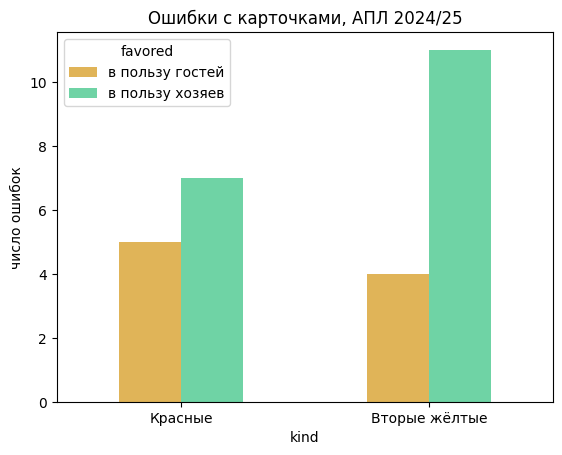

In [31]:
# ЯЧЕЙКА A. Ошибки судей с карточками (данные вшиты в ячейку, загружать файл не нужно)
CSV_TEXT = """kind,date,home,away,player,error,favored,source
second_yellow,2024-09-22,Brighton,Nottingham Forest,Gibbs-White,wrong_second_yellow,home,referee
second_yellow,2024-10-19,Fulham,Aston Villa,Philogene,wrong_second_yellow,home,referee
second_yellow,2024-11-02,Ipswich,Leicester,Phillips,wrong_second_yellow,away,referee
second_yellow,2024-11-23,Bournemouth,Brighton,Baleba,wrong_second_yellow,home,referee
second_yellow,2024-12-07,Crystal Palace,Man City,Lewis,wrong_second_yellow,home,referee
second_yellow,2025-02-15,Aston Villa,Ipswich,Tuanzebe,wrong_second_yellow,home,referee
second_yellow,2025-04-19,Crystal Palace,Bournemouth,Richards,wrong_second_yellow,away,referee
second_yellow,2025-05-10,Bournemouth,Aston Villa,Ramsey,wrong_second_yellow,home,referee
second_yellow,2024-09-29,Ipswich,Aston Villa,Morsy,missed_second_yellow,home,referee
second_yellow,2024-12-01,Tottenham,Fulham,Lukic,missed_second_yellow,away,referee
second_yellow,2024-12-29,Everton,Nottingham Forest,Tarkowski,missed_second_yellow,home,referee
second_yellow,2025-01-26,Aston Villa,West Ham,Alvarez,missed_second_yellow,away,referee
second_yellow,2025-05-10,Southampton,Man City,Ugochukwu,missed_second_yellow,home,referee
second_yellow,2025-05-10,Southampton,Man City,Downes,missed_second_yellow,home,referee
second_yellow,2025-05-25,Nottingham Forest,Chelsea,Anderson,missed_second_yellow,home,referee
red,2024-09-29,Man United,Tottenham,Fernandes,red_not_corrected,away,VAR
red,2024-11-23,Everton,Brentford,Norgaard,red_incorrectly_recommended,home,VAR
red,2024-11-23,Aston Villa,Crystal Palace,Maatsen,red_missed,home,VAR
red,2024-12-21,West Ham,Brighton,Estupinan,red_missed,away,VAR
red,2024-12-27,Brighton,Brentford,Joao Pedro,red_missed,home,VAR
red,2025-01-25,Wolves,Arsenal,Lewis-Skelly,red_not_overturned,home,VAR
red,2025-04-02,Liverpool,Everton,Tarkowski,red_missed,away,VAR
red,2025-04-27,Bournemouth,Man United,Evanilson,red_incorrectly_recommended,away,VAR
red,2024-11-23,Leicester,Chelsea,Ndidi,red_missed,home,referee
red,2024-12-04,Aston Villa,Brentford,Pinnock,red_missed,away,referee
red,2025-03-08,Brentford,Aston Villa,Collins,red_missed,home,referee
red,,Man City,Bournemouth,Lewis Cook,red_incorrect,home,referee
"""

# ===== Блок: ошибки судей с карточками, Premier League 2024/25 =====
# Данные: data/card_errors_2425_all.csv (собраны вручную из списков ESPN по оценкам панели
# Key Match Incidents Premier League). Колонка favored = кому ошибка выгодна: home / away.
import io
import pandas as pd
from scipy.stats import binomtest

errs = pd.read_csv(io.StringIO(CSV_TEXT))

def split(df, label):
    n = len(df)
    k = int((df.favored == "home").sum())
    p = binomtest(k, n, 0.5).pvalue          # точный тест, нулевая гипотеза: 50 на 50
    ci = binomtest(k, n, 0.5).proportion_ci(confidence_level=0.95)
    print(f"{label:<14} всего {n:>2} | в пользу хозяев {k:>2} | в пользу гостей {n-k:>2} | "
          f"доля хозяев {k/n:.2f} [{ci.low:.2f}; {ci.high:.2f}] | p = {p:.3f}")

split(errs, "Все вместе")
split(errs[errs.kind == "second_yellow"], "Вторые жёлтые")
split(errs[errs.kind == "red"], "Красные")

# Простой график
ax = (errs.groupby(["kind", "favored"]).size().unstack(fill_value=0)
          .rename(index={"second_yellow": "Вторые жёлтые", "red": "Красные"},
                  columns={"home": "в пользу хозяев", "away": "в пользу гостей"})
          .plot(kind="bar", rot=0, color=["#E0B458", "#6FD3A5"]))
ax.set_ylabel("число ошибок"); ax.set_title("Ошибки с карточками, АПЛ 2024/25")

In [32]:
# ЯЧЕЙКА B. DSS: решающая сводка, статистика ошибок судей, проверка ассистента
# Запускать в том же ноутбуке после шага 25 (нужны: epl, lg_avg, k, tool_predict, TOOL_FUNCS, TOOLS,
# SYSTEM, ask, validate_free, _nums, LIMITS). Сначала запусти ячейку A (таблица ошибок errs).
import re, json
import pandas as pd
from scipy.stats import binomtest

ERR = errs                       # таблица из ячейки A

# --- справочник судей: во сколько раз каждый судья отклоняется от среднего по АПЛ (сглаженно) ---
_REF = epl.groupby("Referee")["total_y"].agg(["mean", "count"])
_REF = _REF[_REF["count"] >= 30].copy()
_REF["mult"] = (lg_avg + _REF["count"] / (_REF["count"] + k) * (_REF["mean"] - lg_avg)) / lg_avg
MULT_MIN, MULT_MAX = float(_REF["mult"].min()), float(_REF["mult"].max())

# --- правило решения: прозрачное, считает код, а не LLM ---
LOW, HIGH = 0.9, 1.1        # доли от среднего числа жёлтых в матче АПЛ

def risk_level(expected):
    ratio = expected / lg_avg
    return "низкий" if ratio < LOW else ("обычный" if ratio <= HIGH else "повышенный")

ACTIONS = {
    "низкий":     "Дополнительное внимание не требуется.",
    "обычный":    "Стандартный порядок: разбор карточек после матча по общему графику.",
    "повышенный": "Включить матч в список выборочного разбора карточек после игры.",
}

def tool_decision_brief(home, away, referee=None):
    f = tool_predict(home, away, referee)
    if "error" in f:
        return f
    if f["league"] != "Premier League":
        return {"error": "решающая сводка строится только для Премьер-лиги (там есть данные по судьям); "
                         "для других лиг используй predict_match"}
    base = f["model_without_referee"]["expected_yellows_total"]
    if f.get("referee"):
        exp, basis = f["referee"]["with_referee_expected_yellows_total"], "с учётом судьи"
    else:
        exp, basis = base, "без учёта судьи"
    level = risk_level(exp)
    lo, hi = risk_level(base * MULT_MIN), risk_level(base * MULT_MAX)
    return {
        "match": f["match"], "basis": basis, "expected_yellows_total": exp,
        "league_avg_yellows_per_match": round(lg_avg, 2),
        "risk_level": level,
        "risk_if_most_lenient_referee": lo, "risk_if_strictest_referee": hi,
        "decision_robust_to_referee_choice": bool(lo == hi),
        "recommendation": ACTIONS[level],
        "rule": f"риск низкий, если ожидание меньше {LOW} от среднего по АПЛ; "
                f"повышенный, если больше {HIGH}; иначе обычный",
        "context_from_study": "в матчах с болельщиками гости получали примерно на 1.9 карточки на 100 фолов больше "
                              "хозяев, без зрителей разницы не было (связь, причина не доказана)",
        "confidence": "рекомендация основана на ожидании модели; модель лучше простых способов, но ненамного; "
                      "вывод о конкретном судье по ней делать нельзя",
    }

def tool_error_stats():
    out = {}
    for name, d in [("all", ERR), ("second_yellow", ERR[ERR.kind == "second_yellow"]),
                    ("red", ERR[ERR.kind == "red"])]:
        n, kk = len(d), int((d.favored == "home").sum())
        out[name] = {"total": n, "favoured_home": kk, "favoured_away": n - kk,
                     "p_value": float(round(binomtest(kk, n, 0.5).pvalue, 2))}
    out["note"] = ("Премьер-лига 2024/25, ошибки с карточками по спискам ESPN; перекос не доказан, "
                   "выборка мала; одиночные жёлтые панель не разбирает")
    return out

TOOL_FUNCS["decision_brief"] = tool_decision_brief
TOOL_FUNCS["error_stats"] = tool_error_stats
TOOLS += [
 {"name": "decision_brief",
  "description": "Решающая сводка по матчу АПЛ: ожидаемые жёлтые, уровень риска, рекомендация для судейского комитета, "
                 "проверка устойчивости к выбору судьи. Только для Премьер-лиги.",
  "input_schema": {"type": "object",
                   "properties": {"home": {"type": "string"}, "away": {"type": "string"},
                                  "referee": {"type": "string", "description": "фамилия судьи, необязательно"}},
                   "required": ["home", "away"]}},
 {"name": "error_stats",
  "description": "Ошибки судей с карточками в АПЛ 2024/25: сколько выгодны хозяевам и гостям, p-value.",
  "input_schema": {"type": "object", "properties": {}}},
]
SYSTEM = SYSTEM.replace("отвечай, что этого в данных нет", "отвечай, что этот инструмент этого не делает")
SYSTEM += ("\n6. Если просят оценить матч или сказать, нужно ли внимание комитета, вызови decision_brief и перескажи: "
           "риск, рекомендацию, устойчивость к выбору судьи и правило. Рекомендацию не меняй и не усиливай.\n"
           "7. Про ошибки судей с карточками вызови error_stats и обязательно скажи, что перекос не доказан и выборка мала.")

# ===== Проверка качества ассистента: набор тестовых вопросов =====
TESTS = [
 ("Что делать комитету с матчем Chelsea — Man United, судья Bankes?",       {"decision_brief"}),
 ("Оцени матч Liverpool — Man City, нужен ли дополнительный контроль?",     {"decision_brief"}),
 ("Прогноз жёлтых карточек Bayern Munich — Dortmund",                       {"predict_match"}),
 ("Ошибки судей с карточками чаще в пользу хозяев?",                        {"error_stats"}),
 ("Какие судьи АПЛ дают больше всего жёлтых?",                              {"list_referees"}),
 ("Расскажи про судью Bankes",                                              {"referee_profile"}),
 ("Правда ли, что судья Bankes предвзят к гостям?",                         {"referee_profile"}),
 ("Chelsea — Barcelona, сколько жёлтых?",                                   {"predict_match"}),
 ("Кто победит в матче Liverpool — Man City?",                              set()),
 ("Был ли офсайд у Холанда в прошлом матче?",                               set()),
]

def run_eval():
    rows = []
    for q, expected in TESTS:
        used = []
        orig = dict(TOOL_FUNCS)
        for name, fn in orig.items():
            TOOL_FUNCS[name] = (lambda n, f: (lambda **kw: (used.append(n), f(**kw))[1]))(name, fn)
        try:
            text = ask(q)
        finally:
            TOOL_FUNCS.update(orig)
        tool_ok = (set(used) == expected) if not expected else expected.issubset(set(used))
        valid = not text.startswith("Ответ LLM не прошёл проверку")
        rows.append({"вопрос": q, "нужный_инструмент": tool_ok, "числа_прошли_проверку": valid,
                     "ответ": text})
    res = pd.DataFrame(rows)
    print("Нужный инструмент вызван (или отказ без инструмента):", res["нужный_инструмент"].mean())
    print("Ответ прошёл проверку чисел:", res["числа_прошли_проверку"].mean())
    return res

# Запуск: res = run_eval(); затем прочитай столбец «ответ» глазами:
#   - про победителя и офсайд ассистент должен отказаться;
#   - про «предвзят к гостям» не должно быть утвердительного ответа;
#   - в ответе про ошибки должно быть, что перекос не доказан.

In [33]:
print(ask("Что делать комитету с матчем Chelsea — Man United, судья Bankes?"))

  [инструмент] decision_brief({'home': 'Chelsea', 'away': 'Man United', 'referee': 'Bankes'})
**Рекомендация комитету:** включить матч Chelsea — Man United в список выборочного разбора карточек после игры.

- **Ожидаемые жёлтые:** 4.28 за матч, с учётом судьи Bankes. Среднее по АПЛ — 3.5.
- **Уровень риска:** повышенный. Правило такое: риск повышенный, если ожидание больше 1.1 от среднего по лиге. Он низкий, если ожидание меньше 0.9 от среднего. В остальных случаях он обычный.
- **Устойчивость к выбору судьи:** вывод неустойчив. С самым мягким судьёй из списка риск был бы низким. С самым «жёстким» по статистике он остался бы повышенным. Значит, на уровень риска заметно влияет то, кто судит.
- **Контекст из исследования:** в матчах с болельщиками гости получали примерно на 1.9 карточки на 100 фолов больше хозяев. Без зрителей разницы не было. Это связь, причина не доказана.

Прогноз вероятностный. Модель не знает составов и важности матча. Улучшение точности от поправки на судью статист

In [34]:
res = run_eval()

  [инструмент] decision_brief({'home': 'Chelsea', 'away': 'Man United', 'referee': 'Bankes'})
  [инструмент] decision_brief({'home': 'Liverpool', 'away': 'Man City'})
  [инструмент] predict_match({'home': 'Bayern Munich', 'away': 'Dortmund'})
  [инструмент] error_stats({})
  [инструмент] list_referees({})
  [проверка] отклонено, чисел нет в данных: [1.0, 2.0, 3.0]
  [инструмент] referee_profile({'name': 'Bankes'})
  [инструмент] referee_profile({'name': 'Bankes'})
  [инструмент] error_stats({})
  [инструмент] predict_match({'home': 'Chelsea', 'away': 'Barcelona'})
Нужный инструмент вызван (или отказ без инструмента): 1.0
Ответ прошёл проверку чисел: 1.0


In [35]:
pd.set_option("display.max_colwidth", None)
for _, r in res.iterrows():
    print("\nВОПРОС:", r["вопрос"], "\nОТВЕТ:", r["ответ"])


ВОПРОС: Что делать комитету с матчем Chelsea — Man United, судья Bankes? 
ОТВЕТ: **Рекомендация комитету:** включить матч Chelsea — Man United в список выборочного разбора карточек после игры.

- **Ожидание:** примерно 4.28 жёлтых за матч. Средний показатель по АПЛ — 3.5.
- **Риск:** повышенный. Это считается с учётом судьи Bankes.
- **Устойчивость к выбору судьи:** вывод не устойчив. Если назначить самого мягкого судью, риск будет низким. Если назначить самого строгого, риск останется повышенным.
- **Правило:** риск низкий, если ожидание меньше 0.9 от среднего по АПЛ. Он повышенный, если ожидание больше 1.1 от среднего. В остальных случаях он обычный.

Дополнительно из исследования: в матчах с болельщиками гости получали примерно на 1.9 карточки на 100 фолов больше хозяев. Без зрителей разницы не было. Это связь, причина не доказана.

**Важно:** прогноз вероятностный. Модель не знает составов и важности матча. Улучшение точности от поправки на судью статистически не доказано. По этой

In [36]:
def validate_free(text, tool_log, question):
    text = re.sub(r"(?m)^\s*(?:[-*]\s*)?\d+[.)]\s", "", text)   # не считать нумерацию списков числами
    allowed = _nums(json.dumps(tool_log, ensure_ascii=False)) | _nums(" ".join(LIMITS)) | _nums(question)
    return sorted(_nums(text) - allowed)


In [37]:
def chat():
    print("Задавай вопросы про жёлтые карточки, судей АПЛ и ошибки судей. Чтобы выйти, напиши: выход")
    history = []
    while True:
        q = input("\nТы: ").strip()
        if q.lower() in ("выход", "exit", "quit"):
            print("Конец."); break
        if not q:
            continue
        ctx = "".join(f"Прошлый вопрос: {a}\nПрошлый ответ: {b}\n\n" for a, b in history[-2:])
        ans = ask(f"Контекст диалога (для уточняющих вопросов):\n{ctx}Новый вопрос: {q}" if history else q)
        print("\nАссистент:", ans)
        history.append((q, ans))

chat()

Задавай вопросы про жёлтые карточки, судей АПЛ и ошибки судей. Чтобы выйти, напиши: выход

Ты: какой будет матч скоро

Ассистент: Расписание матчей я показать не могу: у меня нет такого инструмента. Я умею только прогнозировать число жёлтых карточек и показывать данные по судьям АПЛ.

Чтобы сделать прогноз, назовите хозяев и гостей. Судью можно не указывать. Например: «Chelsea — Man United».

Если нужна оценка для судейского комитета, я сделаю сводку по матчу АПЛ с уровнем риска и рекомендацией.

Ты: Bornmut- Leeds
  [инструмент] predict_match({'home': 'Bournemouth', 'away': 'Leeds'})

Ассистент: Я понял запрос как «Bournemouth — Leeds» (хозяева — гости). Судья не указан.

**Ожидаемые жёлтые карточки:**
- Bournemouth: 1.72
- Leeds: 1.99
- Всего в матче: 3.7

**Вероятность набрать не меньше k карточек:**
- 3 и больше: 72%
- 4 и больше: 51%
- 5 и больше: 31%
- 6 и больше: 17%

Прогноз основан на форме команд за последние 6 матчей, данные до 2026-10-25.

Если назовёте судью, я учту его в 